# Effect of the discount factor (gamma) on DQN: LunarLander

**Research question.** How does the discount factor `gamma` change the learning speed, stability and final landing quality of a DQN agent on LunarLander?

**Design.** Everything is held fixed (network, optimizer, replay buffer, exploration schedule, update frequency) and only `gamma` is varied over
`[0.995, 0.99, 0.95, 0.9, 0.895, 0.89, 0.85, 0.8]`.

**What is recorded for every run** (saved to disk immediately, so a Colab disconnect never loses finished runs):
per-episode reward and length, the episode at which the task was solved (if ever), a 20-episode greedy evaluation of the final policy,
wall-clock time, and the final network weights. While a run is in progress, a resumable checkpoint (networks, replay buffer, history) is also written every 25 episodes.

**Algorithm reference.** Mnih et al., *Human-level control through deep reinforcement learning*, Nature 518 (2015).
Environment: [Gymnasium LunarLander](https://gymnasium.farama.org/environments/box2d/lunar_lander/).
This notebook is an independent implementation written for this experiment.

## 0. What should we expect? (written before running)

With discount factor `gamma`, the agent effectively looks about `1 / (1 - gamma)` steps ahead.
LunarLander gives its largest reward signal (+100 for landing, -100 for crashing) at the *end* of an episode, so a short horizon
could make that signal almost invisible from states that are far from the ground. The table below quantifies this.

In [ ]:
import numpy as np
import pandas as pd

GAMMAS_PREVIEW = [0.995, 0.99, 0.95, 0.9, 0.895, 0.89, 0.85, 0.8]
horizon_table = pd.DataFrame({
    "gamma": GAMMAS_PREVIEW,
    "effective_horizon (1/(1-g))": [1 / (1 - g) for g in GAMMAS_PREVIEW],
    "value of +100 seen from 50 steps away": [100 * g**50 for g in GAMMAS_PREVIEW],
    "value of +100 seen from 100 steps away": [100 * g**100 for g in GAMMAS_PREVIEW],
}).round(3)
horizon_table

,gamma,effective_horizon (1/(1-g)),value of +100 seen from 50 steps away,value of +100 seen from 100 steps away
0,0.995,200.000,77.831,60.577
1,0.990,100.000,60.501,36.603
2,0.950,20.000,7.694,0.592
3,0.900,10.000,0.515,0.003
4,0.895,9.524,0.390,0.002
5,0.890,9.091,0.295,0.001
6,0.850,6.667,0.030,0.000
7,0.800,5.000,0.001,0.000


**Hypotheses (edit these before you run the sweep, then compare with the results at the end):**

- **H1.** `gamma >= 0.99` reaches the solve criterion (mean reward >= 200 over 100 episodes) within the episode budget.
- **H2.** Learning gets slower and less stable as `gamma` decreases, because the terminal landing/crash reward is discounted away from distant states.
- **H3 (speculative).** Very small `gamma` (<= 0.85) does not learn to land reliably; episodes may become long (hovering) because short-term shaping rewards dominate.

## 1. Setup

In [ ]:
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    # Box2D needs swig to build; tf_keras keeps the classic Keras API available on newer TensorFlow.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "swig"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gymnasium[box2d]", "tf_keras"], check=True)

if "tensorflow" in sys.modules:
    print("WARNING: TensorFlow was already imported. If you hit Keras errors, restart the runtime and run this cell first.")

In [ ]:
os.environ["TF_USE_LEGACY_KERAS"] = "1"      # must be set BEFORE importing tensorflow
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import json, time, platform, tempfile, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import gymnasium as gym


EXPERIMENT = "01_gamma_sweep"
REPO_URL = "https://github.com/mjsafy/dqn-lunarlander-experiments"

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/dqn_lunar") / EXPERIMENT
else:
    def _find_repo_root():
        here = Path.cwd().resolve()
        for p in [here, *here.parents]:
            if (p / ".git").exists():
                return p
        return here          # not inside a git checkout: fall back to the current folder
    ROOT = _find_repo_root() / "results" / EXPERIMENT

RUNS_DIR = ROOT / "runs"
FIG_DIR = ROOT / "figures"
for d in (RUNS_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)


def get_code_commit():
    """Commit of the code that produced these results (so every result maps to a repo version).
    Local: HEAD of the checkout. Colab: latest commit on the remote main branch,
    so PUSH the notebook BEFORE running it."""
    try:
        if IN_COLAB:
            out = subprocess.run(["git", "ls-remote", REPO_URL, "HEAD"],
                                 capture_output=True, text=True, timeout=30, check=True).stdout
            return out.split()[0]
        out = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True,
                             timeout=30, check=True, cwd=ROOT).stdout
        return out.strip()
    except Exception as e:
        return f"unknown ({type(e).__name__})"


env_info = {
    "experiment": EXPERIMENT,
    "code_commit": get_code_commit(),
    "python": platform.python_version(),
    "tensorflow": tf.__version__,
    "gymnasium": gym.__version__,
    "numpy": np.__version__,
    "platform": platform.platform(),
    "cpu_count": os.cpu_count(),
}
(ROOT / "env_info.json").write_text(json.dumps(env_info, indent=2))
print(json.dumps(env_info, indent=2))
print("Results directory:", ROOT.resolve())

Mounted at /content/drive
{
  "python": "3.13.16",
  "tensorflow": "2.21.0",
  "gymnasium": "1.3.0",
  "numpy": "2.1.3",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "cpu_count": 2
}
Results directory: /content/drive/MyDrive/dqn_lunar/gamma_sweep


## 2. Experiment configuration

All hyperparameters live in one dictionary so that each saved run records exactly how it was produced.
Only `gammas` is the experimental variable.

In [ ]:
CONFIG = {
    "env_id": "LunarLander-v3",
    "gammas": [0.995, 0.99, 0.95, 0.9, 0.895, 0.89, 0.85, 0.8],
    "seeds": [0],                 # start with one seed; add more (e.g. [0, 1, 2]) once the pipeline is validated
    "max_episodes": 800,          # hard cap per run; runs that never reach the criterion stop here
    "solve_threshold": 200.0,     # mean training reward over `solve_window` episodes
    "solve_window": 100,
    "buffer_size": 100_000,
    "batch_size": 64,
    "lr": 1e-3,
    "tau": 1e-3,                  # soft target-network update rate
    "update_every": 4,            # one gradient step every N environment steps
    "eps_start": 1.0,
    "eps_decay": 0.995,           # multiplied once per episode
    "eps_min": 0.01,
    "hidden_units": 64,
    "n_eval_episodes": 20,        # greedy evaluation episodes after training
    "checkpoint_every": 25,       # save a resumable checkpoint every N episodes (0 = off)
}

# Stop launching NEW runs after this many minutes (protects against Colab session limits). None = no limit.
MAX_WALL_MINUTES = None

## 3. DQN components

Three pieces: a NumPy replay buffer, a small Q-network builder, and an agent that owns the online network, the target network and the update rule.

In [ ]:
class ReplayBuffer:
    """Fixed-size circular replay buffer backed by pre-allocated NumPy arrays."""

    def __init__(self, capacity, state_dim, rng):
        self.capacity = capacity
        self.rng = rng
        self.states = np.zeros((capacity, state_dim), dtype=np.float32)
        self.actions = np.zeros(capacity, dtype=np.int32)
        self.rewards = np.zeros(capacity, dtype=np.float32)
        self.next_states = np.zeros((capacity, state_dim), dtype=np.float32)
        self.terminals = np.zeros(capacity, dtype=np.float32)
        self._next_idx = 0
        self.size = 0

    def add(self, state, action, reward, next_state, terminal):
        i = self._next_idx
        self.states[i] = state
        self.actions[i] = action
        self.rewards[i] = reward
        self.next_states[i] = next_state
        self.terminals[i] = float(terminal)
        self._next_idx = (i + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size):
        idx = self.rng.integers(0, self.size, size=batch_size)
        return (self.states[idx], self.actions[idx], self.rewards[idx],
                self.next_states[idx], self.terminals[idx])

    def save(self, path):
        n = self.size
        np.savez(path, states=self.states[:n], actions=self.actions[:n], rewards=self.rewards[:n],
                 next_states=self.next_states[:n], terminals=self.terminals[:n],
                 next_idx=self._next_idx, size=n)

    def load(self, path):
        with np.load(path) as z:
            n = int(z["size"])
            self.states[:n] = z["states"]
            self.actions[:n] = z["actions"]
            self.rewards[:n] = z["rewards"]
            self.next_states[:n] = z["next_states"]
            self.terminals[:n] = z["terminals"]
            self._next_idx = int(z["next_idx"])
            self.size = n

In [ ]:
def build_qnet(state_dim, n_actions, hidden_units):
    """State -> one Q-value per action (linear output, since Q-values are unbounded)."""
    return tf.keras.Sequential([
        tf.keras.Input(shape=(state_dim,)),
        tf.keras.layers.Dense(hidden_units, activation="relu"),
        tf.keras.layers.Dense(hidden_units, activation="relu"),
        tf.keras.layers.Dense(n_actions, activation="linear"),
    ])


class DQNAgent:
    """DQN with a soft-updated target network. `gamma` is the only parameter varied in this study."""

    def __init__(self, state_dim, n_actions, cfg, gamma, seed):
        self.n_actions = n_actions
        self.tau = cfg["tau"]
        self.gamma = tf.constant(gamma, dtype=tf.float32)
        self.rng = np.random.default_rng(seed)

        self.q = build_qnet(state_dim, n_actions, cfg["hidden_units"])
        self.target = build_qnet(state_dim, n_actions, cfg["hidden_units"])
        self.target.set_weights(self.q.get_weights())
        self.optimizer = tf.keras.optimizers.Adam(learning_rate=cfg["lr"])

        self._greedy = tf.function(self._greedy_impl)
        self._train = tf.function(self._train_impl)

    # ---- acting
    def _greedy_impl(self, state):
        q_values = self.q(tf.expand_dims(state, 0), training=False)
        return tf.argmax(q_values[0])

    def act(self, state, epsilon):
        if epsilon > 0.0 and self.rng.random() < epsilon:
            return int(self.rng.integers(self.n_actions))
        return int(self._greedy(tf.convert_to_tensor(state, dtype=tf.float32)))

    # ---- learning
    def _train_impl(self, states, actions, rewards, next_states, terminals):
        # Bellman target from the (slowly moving) target network; no gradient flows through it.
        next_q = tf.reduce_max(self.target(next_states, training=False), axis=1)
        targets = rewards + self.gamma * next_q * (1.0 - terminals)

        with tf.GradientTape() as tape:
            q_all = self.q(states, training=True)
            rows = tf.range(tf.shape(actions)[0])
            q_taken = tf.gather_nd(q_all, tf.stack([rows, actions], axis=1))
            loss = tf.reduce_mean(tf.square(tf.stop_gradient(targets) - q_taken))

        grads = tape.gradient(loss, self.q.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.q.trainable_variables))

        # Soft update: target <- tau * online + (1 - tau) * target
        for w_t, w in zip(self.target.trainable_variables, self.q.trainable_variables):
            w_t.assign(self.tau * w + (1.0 - self.tau) * w_t)
        return loss

    def learn(self, batch):
        return self._train(*batch)

    # ---- checkpoint helpers (networks only; Adam's moment estimates are not restored)
    def save_weights_to(self, directory):
        self.q.save_weights(str(Path(directory) / "q.weights.h5"))
        self.target.save_weights(str(Path(directory) / "target.weights.h5"))

    def load_weights_from(self, directory):
        self.q.load_weights(str(Path(directory) / "q.weights.h5"))
        self.target.load_weights(str(Path(directory) / "target.weights.h5"))

## 4. Training and evaluation

Design notes:

- **Terminal vs. truncated.** An episode that ends because the 1000-step time limit was hit (`truncated`) is *not* a true terminal state, so the Bellman target still bootstraps from the next state.
  Only `terminated` (landed or crashed) zeroes the bootstrap term. The loop itself stops on either.
- **Update schedule.** One gradient step every `update_every` environment steps, counted globally across episodes.
- **Atomic saves.** Results are written to a temporary file and then renamed, so an interrupted save cannot leave a half-written result.
- **Finished runs are never repeated.** A run counts as finished only if its `.npz` file exists; the sweep skips finished runs.
- **Mid-run checkpoints.** Every `checkpoint_every` episodes the online and target networks, the replay buffer, epsilon and the reward history are saved into one of two alternating slots (`ckpt_<run>_a/b`).
  A slot is valid only if its small `meta.npz` file exists, and that file is written last, so a crash while writing never destroys the previous checkpoint.
  If a run is interrupted, calling the sweep again resumes it from the newest valid checkpoint. Checkpoints are deleted when the run finishes.
  Not restored: Adam's moment estimates and the random-number streams (they are re-seeded from the seed and episode number), so a resumed run is valid but not bit-identical to an uninterrupted one.

In [ ]:
def run_name(gamma, seed):
    return f"gamma{gamma:.3f}_seed{seed}"


def set_global_seeds(seed):
    np.random.seed(seed)
    tf.random.set_seed(seed)


def evaluate_greedy(agent, env_id, n_episodes, seed):
    """Run the final policy with epsilon = 0 and return the episode returns."""
    env = gym.make(env_id)
    returns = []
    for i in range(n_episodes):
        state, _ = env.reset(seed=seed + i)
        done, total = False, 0.0
        while not done:
            action = agent.act(state, epsilon=0.0)
            state, reward, terminated, truncated, _ = env.step(action)
            total += reward
            done = terminated or truncated
        returns.append(total)
    env.close()
    return np.array(returns, dtype=np.float64)


# ---- mid-run checkpointing ---------------------------------------------------
def _slot_dirs(runs_dir, name):
    return {s: Path(runs_dir) / f"ckpt_{name}_{s}" for s in ("a", "b")}


def _slot_episode(slot_dir):
    """Episode count stored in a checkpoint slot, or -1 if the slot is missing or incomplete."""
    meta = Path(slot_dir) / "meta.npz"
    if not meta.exists():
        return -1
    try:
        with np.load(meta) as z:
            return int(z["episode"])
    except Exception:
        return -1


def save_checkpoint(runs_dir, name, agent, buffer, meta):
    """Write into the older of two slots. meta.npz is written last, so a half-written slot is never valid."""
    dirs = _slot_dirs(runs_dir, name)
    older = min(dirs, key=lambda s: _slot_episode(dirs[s]))
    d = dirs[older]
    d.mkdir(parents=True, exist_ok=True)
    (d / "meta.npz").unlink(missing_ok=True)          # invalidate the slot before overwriting it
    agent.save_weights_to(d)
    buffer.save(d / "buffer.npz")
    tmp = d / "tmp_meta.npz"
    np.savez(tmp, **meta)
    os.replace(tmp, d / "meta.npz")


def load_checkpoint(runs_dir, name, agent, buffer):
    """Restore the newest valid checkpoint. Returns (meta or None, a_load_failed_flag)."""
    dirs = _slot_dirs(runs_dir, name)
    failed = False
    for s in sorted(dirs, key=lambda k: _slot_episode(dirs[k]), reverse=True):
        d = dirs[s]
        if _slot_episode(d) < 0:
            continue
        try:
            with np.load(d / "meta.npz") as z:
                meta = {k: z[k] for k in z.files}
            agent.load_weights_from(d)
            buffer.load(d / "buffer.npz")
            return meta, failed
        except Exception as e:
            failed = True
            print(f"[warn] could not load checkpoint {d.name}: {e}")
    return None, failed


def clear_checkpoints(runs_dir, name):
    for d in _slot_dirs(runs_dir, name).values():
        shutil.rmtree(d, ignore_errors=True)


# ---- training ----------------------------------------------------------------
def train_one_run(gamma, seed, cfg, runs_dir, verbose=True, _interrupt_after=None):
    """Train one (gamma, seed) run (resuming from a checkpoint if one exists), evaluate it,
    save everything, and return the result path. `_interrupt_after` is for the smoke test only."""
    runs_dir = Path(runs_dir)
    name = run_name(gamma, seed)
    set_global_seeds(seed)

    env = gym.make(cfg["env_id"])
    state_dim = env.observation_space.shape[0]
    n_actions = env.action_space.n

    def fresh():
        return (DQNAgent(state_dim, n_actions, cfg, gamma, seed),
                ReplayBuffer(cfg["buffer_size"], state_dim, np.random.default_rng(seed + 1)))

    agent, buffer = fresh()
    epsilon = cfg["eps_start"]
    rewards, lengths = [], []
    total_steps, start_episode, prior_seconds = 0, 0, 0.0
    solved_at = -1

    meta, load_failed = load_checkpoint(runs_dir, name, agent, buffer)
    if meta is not None:
        start_episode = int(meta["episode"])
        epsilon = float(meta["epsilon"])
        total_steps = int(meta["total_steps"])
        prior_seconds = float(meta["elapsed"])
        rewards = [float(x) for x in meta["rewards"]]
        lengths = [int(x) for x in meta["lengths"]]
        agent.rng = np.random.default_rng([seed, start_episode])
        buffer.rng = np.random.default_rng([seed, start_episode, 1])
        print(f"[{name}] resumed from checkpoint at episode {start_episode}")
    elif load_failed:
        agent, buffer = fresh()          # a failed load may have left the objects half-restored

    t_start = time.time()
    elapsed = lambda: prior_seconds + (time.time() - t_start)
    window = cfg["solve_window"]

    for episode in range(start_episode, cfg["max_episodes"]):
        reset_seed = None
        if episode == start_episode:
            reset_seed = seed if start_episode == 0 else seed * 1_000_003 + start_episode
        state, _ = env.reset(seed=reset_seed)
        ep_reward, ep_len, done = 0.0, 0, False

        while not done:
            action = agent.act(state, epsilon)
            next_state, reward, terminated, truncated, _ = env.step(action)
            buffer.add(state, action, reward, next_state, terminated)

            state = next_state
            ep_reward += reward
            ep_len += 1
            total_steps += 1
            done = terminated or truncated

            if total_steps % cfg["update_every"] == 0 and buffer.size >= cfg["batch_size"]:
                agent.learn(buffer.sample(cfg["batch_size"]))

        rewards.append(ep_reward)
        lengths.append(ep_len)
        epsilon = max(cfg["eps_min"], epsilon * cfg["eps_decay"])

        avg = float(np.mean(rewards[-window:]))
        if verbose and ((episode + 1) % 50 == 0 or episode == start_episode):
            print(f"[{name}] ep {episode + 1:4d} | avg{window} {avg:8.2f} | eps {epsilon:.3f} "
                  f"| {elapsed() / 60:5.1f} min")
        if len(rewards) >= window and avg >= cfg["solve_threshold"]:
            solved_at = episode + 1
            break

        every = cfg.get("checkpoint_every", 0)
        if every and (episode + 1) % every == 0:
            save_checkpoint(runs_dir, name, agent, buffer, dict(
                episode=episode + 1, epsilon=epsilon, total_steps=total_steps, elapsed=elapsed(),
                rewards=np.array(rewards, dtype=np.float64), lengths=np.array(lengths, dtype=np.int32)))
            if _interrupt_after is not None and episode + 1 >= _interrupt_after:
                raise RuntimeError("simulated interruption (smoke test only)")

    env.close()
    train_time = elapsed()

    eval_returns = evaluate_greedy(agent, cfg["env_id"], cfg["n_eval_episodes"], seed=10_000 + 100 * seed)

    # Weights first, results file last: the .npz existing means the run is complete.
    agent.q.save_weights(str(runs_dir / f"{name}_q.weights.h5"))
    path = runs_dir / f"{name}.npz"
    tmp = runs_dir / f"tmp_{name}.npz"
    np.savez_compressed(
        tmp,
        gamma=gamma, seed=seed,
        rewards=np.array(rewards, dtype=np.float64),
        lengths=np.array(lengths, dtype=np.int32),
        solved_at=solved_at, wall_time=train_time, total_steps=total_steps,
        eval_returns=eval_returns, config=json.dumps(cfg),
    )
    os.replace(tmp, path)
    clear_checkpoints(runs_dir, name)

    if verbose:
        status = f"solved in {solved_at} episodes" if solved_at > 0 else "NOT solved"
        print(f"[{name}] done: {status} | greedy eval mean {eval_returns.mean():.1f} "
              f"(std {eval_returns.std():.1f}) | {train_time / 60:.1f} min")
    return path


def run_sweep(cfg, runs_dir, max_wall_minutes=None):
    """Run every (seed, gamma) pair that has no saved result yet. Seeds are the outer loop,
    so after the first pass you already have a complete sweep for one seed."""
    t0 = time.time()
    for seed in cfg["seeds"]:
        for gamma in cfg["gammas"]:
            path = Path(runs_dir) / f"{run_name(gamma, seed)}.npz"
            if path.exists():
                print(f"[skip] {path.name} already finished")
                continue
            if max_wall_minutes is not None and (time.time() - t0) / 60 > max_wall_minutes:
                print(f"Wall-clock budget of {max_wall_minutes} min reached; stopping before {path.name}.")
                return
            train_one_run(gamma, seed, cfg, runs_dir)
    print("Sweep finished.")

## 5. Smoke test

A tiny run in a temporary folder (not in your results) that checks the whole pipeline, **including crash recovery**:
the run is deliberately interrupted right after the checkpoint at episode 4, then restarted and must resume from that checkpoint and finish.
Episode length grows as the agent learns to fly longer, so treat the steps-per-second figure as the more useful number for planning.

In [ ]:
smoke_dir = Path(tempfile.mkdtemp(prefix="dqn_smoke_"))
smoke_cfg = {**CONFIG, "max_episodes": 8, "n_eval_episodes": 2, "checkpoint_every": 2}

t0 = time.time()
try:
    train_one_run(0.99, 0, smoke_cfg, smoke_dir, _interrupt_after=4)
except RuntimeError as e:
    print("Interrupted as planned:", e)
print("On disk after the interruption:", sorted(p.name for p in smoke_dir.iterdir()))

smoke_path = train_one_run(0.99, 0, smoke_cfg, smoke_dir)      # must print "resumed from checkpoint at episode 4"
elapsed_total = time.time() - t0

assert not list(smoke_dir.glob("ckpt_*")), "checkpoints should be removed after a finished run"
with np.load(smoke_path) as z:
    steps = int(z["total_steps"])
    assert len(z["rewards"]) == 8
    print(f"\nLoaded back OK. Episodes: {len(z['rewards'])}, steps: {steps}")
print(f"Total smoke-test time: {elapsed_total:.1f} s  (~{steps / max(elapsed_total, 1e-9):.0f} env steps/s incl. learning, saving and evaluation)")
shutil.rmtree(smoke_dir, ignore_errors=True)

[gamma0.990_seed0] ep    1 | avg100     2.96 | eps 0.995 |   0.0 min
Interrupted as planned: simulated interruption (smoke test only)
On disk after the interruption: ['ckpt_gamma0.990_seed0_a', 'ckpt_gamma0.990_seed0_b']
[gamma0.990_seed0] resumed from checkpoint at episode 4
[gamma0.990_seed0] ep    5 | avg100   -92.30 | eps 0.975 |   0.0 min
[gamma0.990_seed0] done: NOT solved | greedy eval mean -632.1 (std 52.6) | 0.0 min

Loaded back OK. Episodes: 8, steps: 744
Total smoke-test time: 2.2 s  (~345 env steps/s incl. learning, saving and evaluation)


## 6. Run the sweep

Safe to interrupt and re-run: finished runs are skipped, and an interrupted run resumes from its last checkpoint (at most `checkpoint_every` episodes are lost). Keep the Colab tab open while it runs.
Runs that never reach the solve criterion stop at `max_episodes` and are the slowest; start with one seed to see how long the whole sweep takes on your machine before adding more seeds.

In [ ]:
run_sweep(CONFIG, RUNS_DIR, max_wall_minutes=MAX_WALL_MINUTES)

[skip] gamma0.995_seed0.npz already finished
[skip] gamma0.990_seed0.npz already finished
[skip] gamma0.950_seed0.npz already finished
[skip] gamma0.900_seed0.npz already finished
[gamma0.895_seed0] ep    1 | avg100     2.96 | eps 0.995 |   0.0 min
[gamma0.895_seed0] ep   50 | avg100  -151.43 | eps 0.778 |   0.0 min
[gamma0.895_seed0] ep  100 | avg100  -152.13 | eps 0.606 |   0.1 min
[gamma0.895_seed0] ep  150 | avg100  -135.55 | eps 0.471 |   0.4 min
[gamma0.895_seed0] ep  200 | avg100   -95.43 | eps 0.367 |   0.6 min
[gamma0.895_seed0] ep  250 | avg100   -70.86 | eps 0.286 |   1.0 min
[gamma0.895_seed0] ep  300 | avg100   -74.19 | eps 0.222 |   1.6 min
[gamma0.895_seed0] ep  350 | avg100   -49.60 | eps 0.173 |   2.1 min
[gamma0.895_seed0] ep  400 | avg100    -9.37 | eps 0.135 |   2.7 min
[gamma0.895_seed0] ep  450 | avg100   -29.57 | eps 0.105 |   3.3 min
[gamma0.895_seed0] ep  500 | avg100   -66.88 | eps 0.082 |   4.0 min
[gamma0.895_seed0] ep  550 | avg100   -89.20 | eps 0.063 |   

## 7. Analysis

In [ ]:
def load_runs(runs_dir):
    runs = []
    for f in sorted(Path(runs_dir).glob("gamma*_seed*.npz")):
        with np.load(f, allow_pickle=False) as z:
            runs.append({
                "gamma": float(z["gamma"]), "seed": int(z["seed"]),
                "rewards": z["rewards"], "lengths": z["lengths"],
                "solved_at": int(z["solved_at"]), "wall_time": float(z["wall_time"]),
                "total_steps": int(z["total_steps"]), "eval_returns": z["eval_returns"],
            })
    return runs


def summarize(runs, cfg):
    w = cfg["solve_window"]
    rows = []
    for r in runs:
        solved = r["solved_at"] > 0
        rows.append({
            "gamma": r["gamma"],
            "seed": r["seed"],
            "horizon": 1.0 / (1.0 - r["gamma"]),
            "solved": solved,
            "episodes_run": len(r["rewards"]),
            "episodes_to_solve": r["solved_at"] if solved else np.nan,
            "train_avg_last100": float(np.mean(r["rewards"][-w:])),
            "ep_len_avg_last100": float(np.mean(r["lengths"][-w:])),
            "eval_mean": float(np.mean(r["eval_returns"])),
            "eval_std": float(np.std(r["eval_returns"])),
            "eval_success_rate": float(np.mean(r["eval_returns"] >= cfg["solve_threshold"])),
            "train_minutes": r["wall_time"] / 60.0,
            "total_steps": r["total_steps"],
        })
    return pd.DataFrame(rows).sort_values(["gamma", "seed"], ascending=[False, True]).reset_index(drop=True)


runs = load_runs(RUNS_DIR)
print(f"Loaded {len(runs)} finished runs.")
summary = summarize(runs, CONFIG)
summary.round(3)

Loaded 8 finished runs.


,gamma,seed,horizon,solved,episodes_run,episodes_to_solve,train_avg_last100,ep_len_avg_last100,eval_mean,eval_std,eval_success_rate,train_minutes,total_steps
0,0.995,0,200.000,True,562,562.0,200.116,510.08,187.788,82.427,0.55,5.925,288392
1,0.990,0,100.000,True,722,722.0,201.925,535.43,197.681,72.103,0.50,8.847,415362
2,0.950,0,20.000,False,800,NaN,-66.003,973.31,-52.955,94.172,0.05,12.593,577777
3,0.900,0,10.000,False,800,NaN,-106.204,843.77,-106.015,33.436,0.00,11.405,519048
4,0.895,0,9.524,False,800,NaN,-99.808,964.16,-102.652,40.439,0.00,12.539,563475
5,0.890,0,9.091,False,800,NaN,-113.970,966.28,-107.031,17.758,0.00,11.975,545920
6,0.850,0,6.667,False,800,NaN,-71.192,900.67,-62.112,129.825,0.15,7.110,492196
7,0.800,0,5.000,False,800,NaN,18.664,683.78,86.227,178.628,0.55,5.215,343155


`eval_success_rate` is the fraction of the greedy evaluation episodes whose return is at least `solve_threshold` (200). It is a stricter, per-episode measure than the 100-episode training average used as the stopping rule.

In [ ]:
by_gamma = (summary.groupby("gamma", sort=False)
            .agg(runs=("seed", "count"),
                 solved_runs=("solved", "sum"),
                 episodes_to_solve_mean=("episodes_to_solve", "mean"),
                 train_avg_last100=("train_avg_last100", "mean"),
                 ep_len_avg_last100=("ep_len_avg_last100", "mean"),
                 eval_mean=("eval_mean", "mean"),
                 eval_success_rate=("eval_success_rate", "mean"),
                 train_minutes=("train_minutes", "mean"))
            .round(2))

summary.to_csv(ROOT / "summary_per_run.csv", index=False)
by_gamma.to_csv(ROOT / "summary_by_gamma.csv")
print("Saved:", ROOT / "summary_per_run.csv", "and", ROOT / "summary_by_gamma.csv")
by_gamma

Saved: /content/drive/MyDrive/dqn_lunar/gamma_sweep/summary_per_run.csv and /content/drive/MyDrive/dqn_lunar/gamma_sweep/summary_by_gamma.csv


,runs,solved_runs,episodes_to_solve_mean,train_avg_last100,ep_len_avg_last100,eval_mean,eval_success_rate,train_minutes
gamma,,,,,,,,
0.995,1,1,562.0,200.12,510.08,187.79,0.55,5.92
0.990,1,1,722.0,201.92,535.43,197.68,0.50,8.85
0.950,1,0,NaN,-66.00,973.31,-52.95,0.05,12.59
0.900,1,0,NaN,-106.20,843.77,-106.01,0.00,11.41
0.895,1,0,NaN,-99.81,964.16,-102.65,0.00,12.54
0.890,1,0,NaN,-113.97,966.28,-107.03,0.00,11.97
0.850,1,0,NaN,-71.19,900.67,-62.11,0.15,7.11
0.800,1,0,NaN,18.66,683.78,86.23,0.55,5.21


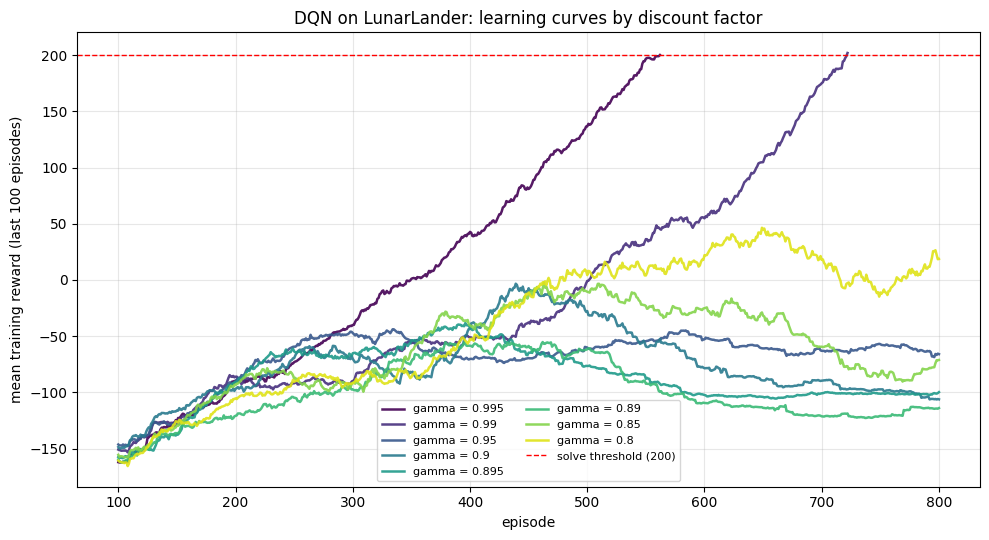

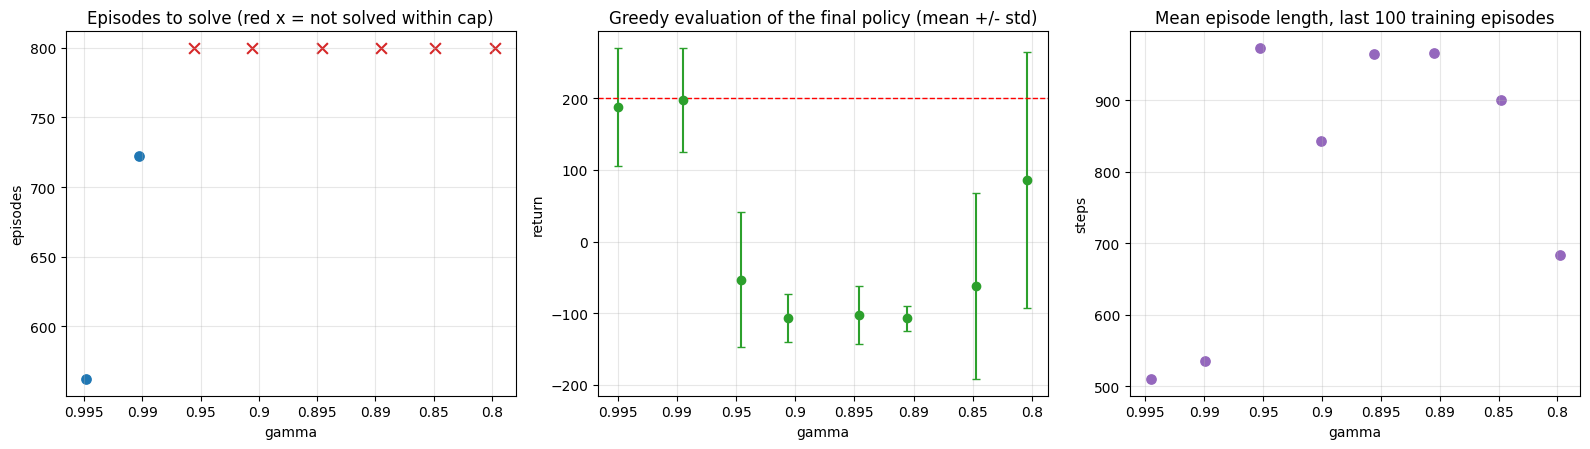

Figures saved to /content/drive/MyDrive/dqn_lunar/gamma_sweep/figures


In [ ]:
def plot_learning_curves(runs, cfg, save_path):
    w = cfg["solve_window"]
    gammas = sorted({r["gamma"] for r in runs}, reverse=True)
    colors = plt.cm.viridis(np.linspace(0, 0.95, max(len(gammas), 2)))
    color_of = {g: colors[i] for i, g in enumerate(gammas)}

    fig, ax = plt.subplots(figsize=(10, 5.5))
    labelled = set()
    for r in sorted(runs, key=lambda r: (-r["gamma"], r["seed"])):
        smooth = pd.Series(r["rewards"]).rolling(w).mean()
        label = f"gamma = {r['gamma']:g}" if r["gamma"] not in labelled else None
        labelled.add(r["gamma"])
        ax.plot(np.arange(1, len(smooth) + 1), smooth, color=color_of[r["gamma"]], lw=1.8, alpha=0.9, label=label)
    ax.axhline(cfg["solve_threshold"], color="red", ls="--", lw=1, label="solve threshold (200)")
    ax.set_xlabel("episode")
    ax.set_ylabel(f"mean training reward (last {w} episodes)")
    ax.set_title("DQN on LunarLander: learning curves by discount factor")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, ncol=2)
    fig.tight_layout()
    fig.savefig(save_path, dpi=150)
    plt.show()


def plot_summary(summary, cfg, save_path):
    gammas = sorted(summary["gamma"].unique(), reverse=True)
    pos = {g: i for i, g in enumerate(gammas)}
    labels = [f"{g:g}" for g in gammas]
    rng = np.random.default_rng(0)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

    # (A) episodes needed; unsolved runs are drawn as red crosses at their episode cap
    ax = axes[0]
    for _, row in summary.iterrows():
        x = pos[row["gamma"]] + rng.uniform(-0.12, 0.12)
        if row["solved"]:
            ax.scatter(x, row["episodes_to_solve"], color="tab:blue", s=45)
        else:
            ax.scatter(x, row["episodes_run"], color="tab:red", marker="x", s=60)
    ax.set_title("Episodes to solve (red x = not solved within cap)")
    ax.set_ylabel("episodes")

    # (B) greedy evaluation of the final policy
    ax = axes[1]
    for _, row in summary.iterrows():
        x = pos[row["gamma"]] + rng.uniform(-0.12, 0.12)
        ax.errorbar(x, row["eval_mean"], yerr=row["eval_std"], fmt="o", color="tab:green", capsize=3)
    ax.axhline(cfg["solve_threshold"], color="red", ls="--", lw=1)
    ax.set_title("Greedy evaluation of the final policy (mean +/- std)")
    ax.set_ylabel("return")

    # (C) episode length: long episodes with low reward suggest hovering instead of landing
    ax = axes[2]
    for _, row in summary.iterrows():
        x = pos[row["gamma"]] + rng.uniform(-0.12, 0.12)
        ax.scatter(x, row["ep_len_avg_last100"], color="tab:purple", s=45)
    ax.set_title("Mean episode length, last 100 training episodes")
    ax.set_ylabel("steps")

    for ax in axes:
        ax.set_xticks(range(len(gammas)))
        ax.set_xticklabels(labels)
        ax.set_xlabel("gamma")
        ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(save_path, dpi=150)
    plt.show()


plot_learning_curves(runs, CONFIG, FIG_DIR / "learning_curves.png")
plot_summary(summary, CONFIG, FIG_DIR / "summary_panels.png")
print("Figures saved to", FIG_DIR)

## 8. Results and conclusions

**What was run:** 8 values of `gamma`, one seed (0), 800-episode cap per run, everything else fixed. Total training time was about 76 minutes on a 2-core Colab CPU (roughly 800 environment steps per second).

### Results at a glance

| gamma | horizon 1/(1-g) | solved | episodes to solve | train avg, last 100 | greedy eval (mean ± std, 20 ep.) | eval success rate | mean episode length, last 100 |
|---|---|---|---|---|---|---|---|
| 0.995 | 200 | yes | 562 | 200.1 | 187.8 ± 82.4 | 55% | 510 |
| 0.99 | 100 | yes | 722 | 201.9 | 197.7 ± 72.1 | 50% | 535 |
| 0.95 | 20 | no | - | -66.0 | -53.0 ± 94.2 | 5% | 973 |
| 0.90 | 10 | no | - | -106.2 | -106.0 ± 33.4 | 0% | 844 |
| 0.895 | 9.5 | no | - | -99.8 | -102.7 ± 40.4 | 0% | 964 |
| 0.89 | 9.1 | no | - | -114.0 | -107.0 ± 17.8 | 0% | 966 |
| 0.85 | 6.7 | no | - | -71.2 | -62.1 ± 129.8 | 15% | 901 |
| 0.80 | 5.0 | no | - | 18.7 | 86.2 ± 178.6 | 55% | 684 |

"Eval success rate" is the share of the 20 greedy evaluation episodes with return >= 200. With 20 episodes its standard error is about 11 percentage points, so 50% vs 55% is not a difference.

### Hypotheses versus outcome

- **H1 (gamma >= 0.99 solves the task): supported**, for one seed. gamma = 0.995 solved it in 562 episodes and gamma = 0.99 in 722.
- **H2 (lower gamma is slower and less stable): partly supported.** There is a clear split between 0.99 (solved) and 0.95 (not solved), and 0.99 was slower than 0.995. Below that split there is *no* monotonic trend: gamma = 0.8 ended up better than 0.95 to 0.85 on both training reward and greedy evaluation.
- **H3 (gamma <= 0.85 does not land reliably, episodes get long): mixed.** Neither run solved the task, and gamma = 0.85 landed in only 15% of evaluation episodes. But gamma = 0.8 matched gamma = 0.995 on success rate (55%) while having a much lower mean return, and its episodes were shorter than those of 0.95 to 0.85. The long-episode pattern showed up most strongly for 0.95 to 0.85.

### What the curves show

1. **All runs look alike for the first ~250 episodes** (mean reward rising from about -150 to about -90). Differences appear afterwards.
2. **The two solved runs take off late.** gamma = 0.99 hovers between roughly -50 and +50 until about episode 550 and then climbs quickly.
3. **Every unsolved run rises and then falls.** Logged peaks of the 100-episode average: gamma = 0.895 about -9 at episode 400, 0.89 about -49 at episode 350, 0.85 about -10 at episode 500, 0.8 about +45 at episode 650. The final values are far below those peaks.
4. **Episodes become almost as long as the 1000-step limit** for gamma = 0.95, 0.895, 0.89 and 0.85 (mean length 900 to 973), while the solved runs average about 510 to 535 steps. Combined with returns around -100, this is consistent with an agent that keeps the lander in the air until the time limit instead of landing. The aggregate numbers cannot confirm this; it needs per-episode diagnostics.
5. **The greedy evaluation of gamma = 0.9, 0.895 and 0.89 has a very small spread** (std 18 to 40) around -105. That looks like one consistent behaviour repeated every episode rather than random crashes.
6. **gamma = 0.8 is bimodal.** A mean of 86 with a std of 179 and 55% successes fits a mix of good landings and crashes. Its training curve also swings by about 55 points between neighbouring 100-episode windows.

### Possible explanations (hypotheses, not established by this experiment)

- **Horizon versus flight time.** The effective horizon is 5 to 20 steps for gamma <= 0.95, but a successful landing here takes roughly 500 steps. For most of the flight the +100/-100 terminal rewards are invisible to the value function, so behaviour is driven by the dense shaping reward and fuel costs.
- **The environment's shaping is not consistent with gamma < 1.** The reward contains `Phi(s_t) - Phi(s_{t-1})`, where `Phi = -100*distance - 100*speed - 100*|angle| + 10*(leg contacts)`. This telescopes only when gamma = 1. For gamma < 1 it equals the policy-preserving form `gamma*Phi(s') - Phi(s)` plus an extra term `(1 - gamma) * Phi(s')` at every step. That extra term is a per-step reward that depends on the *level* of the potential (far, fast or tilted states are penalised continuously), and its weight grows as gamma decreases. The agent is then optimising something different from "land softly", which could favour staying in good states instead of finishing the landing. This is a mathematical fact about the reward; whether it explains the hovering here is untested.
- **Replay buffer flooding.** With episodes near 1000 steps, the 100,000-transition buffer holds only about 100 episodes. Once hovering dominates, the rare terminal transitions (landing, crash) that anchor the Q-values can be evicted, which can cause forgetting and oscillation.
- **Exploration decay.** Training reward is measured under epsilon-greedy. The declines happen while epsilon falls from about 0.17 to 0.02, so random actions may have been masking flaws of the greedy policy. The peaks do not occur at one common epsilon, so this alone does not explain it.
- **Generic DQN instability.** Constant learning rate, squared loss with rewards of magnitude 100, no gradient clipping, and moving bootstrap targets can all cause collapse after a peak.
- **Time-limit handling.** Truncation is treated as non-terminal here, so the agent receives no signal that hovering ends at step 1000. The alternative was not tested.
- **Survivor effect in the solved runs.** Runs stop as soon as the criterion is met, so we do not know whether gamma = 0.995 and 0.99 would also have declined if training had continued.

### What this experiment does not show

- With one seed per gamma, differences between nearby values are not meaningful (for example 0.9 vs 0.895 vs 0.89). Within-run swings of about 50 points are as large as the gaps between most unsolved runs, so they cannot be ranked.
- The ordering among the unsolved runs, including the good showing of gamma = 0.8, may be seed noise.
- The location of the threshold between 0.95 and 0.99 is unknown, and 800 episodes may be too few for some of the unsolved runs.

## 9. Limitations (read before quoting any number)

- **Few seeds.** RL results have high run-to-run variance. Every gamma was run once, so no statistical claim is made.
- **One variable at a time.** Only `gamma` changes. Other settings (learning rate, target update rate, epsilon schedule, buffer size) were not re-tuned per `gamma`.
- **Episode cap.** Unsolved runs stopped at 800 episodes; some might have solved the task with a larger budget.
- **Episodes-to-solve is confounded with the exploration schedule.** Epsilon decays per episode, so the number of episodes depends on `gamma` and on that schedule.
- **Early stopping hides later behaviour.** Solved runs stop at the criterion, so possible later collapse is not observed.
- **Small evaluation sample.** 20 greedy episodes give a coarse success rate (standard error about 11 points).
- **Reward shaping is not gamma-consistent** (see above), so the effect of `gamma` is entangled with how the environment's reward is built.
- **Resumed runs are not bit-identical.** After a crash, Adam's moment estimates and the random streams are not restored. No run in this sweep is known to have been resumed, but check the logs before reporting a run that was.
- **Hardware non-determinism.** Seeds are set, but identical results are not guaranteed across machines or library versions.

## 10. Next experiments

1. **Diagnostics first (cheap, most informative).** Log per-episode termination reason (landed, crashed, time limit), final position and legs, fraction of steps with each action, periodic greedy evaluation every 50 episodes, and mean Q-value and loss. This tests the hovering story and the epsilon-masking story directly.
2. **Keep training after the criterion is met** for gamma = 0.995 and 0.99 to see whether they also collapse.
3. **Gamma-consistent shaping.** Replace the environment reward with `r - (1 - gamma) * Phi(s')` (Phi recomputed from the observation) and repeat the low-gamma runs. If hovering disappears, the shaping mismatch is a major cause. Terminal-state handling of Phi needs care.
4. **Replay buffer size.** Repeat gamma = 0.9 and 0.85 with a buffer of 1,000,000, or keep terminal transitions in a separate buffer.
5. **Several seeds** (3 to 5) for every gamma, plus finer values between 0.95 and 0.99 (for example 0.97 and 0.98) to locate the threshold.
6. **Stability tweaks** (Huber loss, gradient clipping, learning-rate decay) and the alternative time-limit handling, one at a time.
7. **Algorithm comparison:** Double DQN and Dueling DQN against this baseline.